### GDP (Gross Domestic Product) is the total value of everything—goods and services—produced in a business in a specific period of time namely yearly.  You can think of it as the grand total, used to measure the overall size and health of an business. 
### We shall be analysing the Gross Domestic Product of a sales company in December 2025 and predicting the future outcome which may lead to improvement in sales.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('C:/Users/Admin/Desktop/DATA/gross-domestic-product-december-2025-quarter-visualisation.csv')
df.head(5)

,Level,Description,SeriesRefSNDQ,Quarter,Weight,Amount
0,Industry groups,Agriculture,SG01RSC04B01AA1,1987Q2,0.049996,1596.686
1,Industry groups,Forestry and logging,SG01RSC04B01AA2,1987Q2,0.004201,120.463
2,Industry groups,"Fishing, aquaculture and agriculture, forestry...",SG01RSC04B01AA3,1987Q2,0.006766,201.055
3,Industry groups,Mining,SG01RSC04B01BB1,1987Q2,0.014021,530.698
4,Industry groups,"Food, beverage, and tobacco manufacturing",SG01RSC04B01CC1,1987Q2,0.056429,1145.595


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8370 entries, 0 to 8369
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Level          8370 non-null   object 
 1   Description    8370 non-null   object 
 2   SeriesRefSNDQ  8370 non-null   object 
 3   Quarter        8370 non-null   object 
 4   Weight         8370 non-null   float64
 5   Amount         8370 non-null   float64
dtypes: float64(2), object(4)
memory usage: 392.5+ KB


In [4]:
df.describe()

,Weight,Amount
count,8370.000000,8370.000000
mean,0.074074,3468.130434
std,0.154780,7675.568785
min,0.001483,95.438000
25%,0.018623,806.024000
50%,0.042812,1789.193000
75%,0.063242,3014.429750
max,1.000000,70996.972000


In [5]:
df.describe(include='O')

,Level,Description,SeriesRefSNDQ,Quarter
count,8370,8370,8370,8370
unique,4,43,52,155
top,Industry groups,"Rental, hiring, and real estate services",SG01RSC04B01UZ9,1987Q2
freq,4960,310,465,54


In [6]:
# remove all the rows that contain a missing value
dfNEW=df.dropna()
dfNEW.shape

(8370, 6)

In [7]:
# drops all rows
dfNEW.drop_duplicates(keep=False).shape

(8370, 6)

### Let's divide the dataset into numerical and categorical columns.

In [8]:
numerical_cols = ['Weight','Amount']
categorical_cols = ['Level','Description','SeriesRefSNDQ']
target = ['Amount']

### Categorical Features

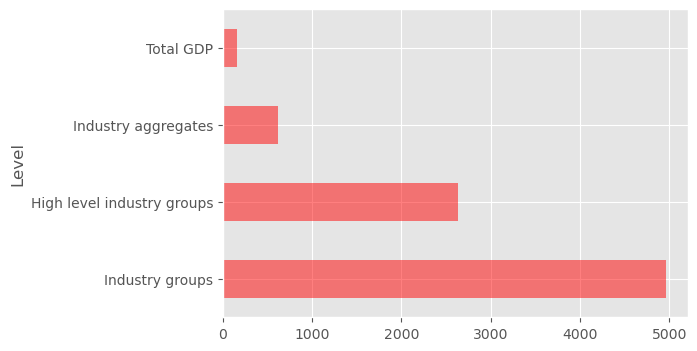

In [9]:
plt.style.use("ggplot")
plt.figure(figsize=(6,4))
df['Level'].value_counts().plot.barh(stacked=True, color='r',alpha=0.5)
plt.show()

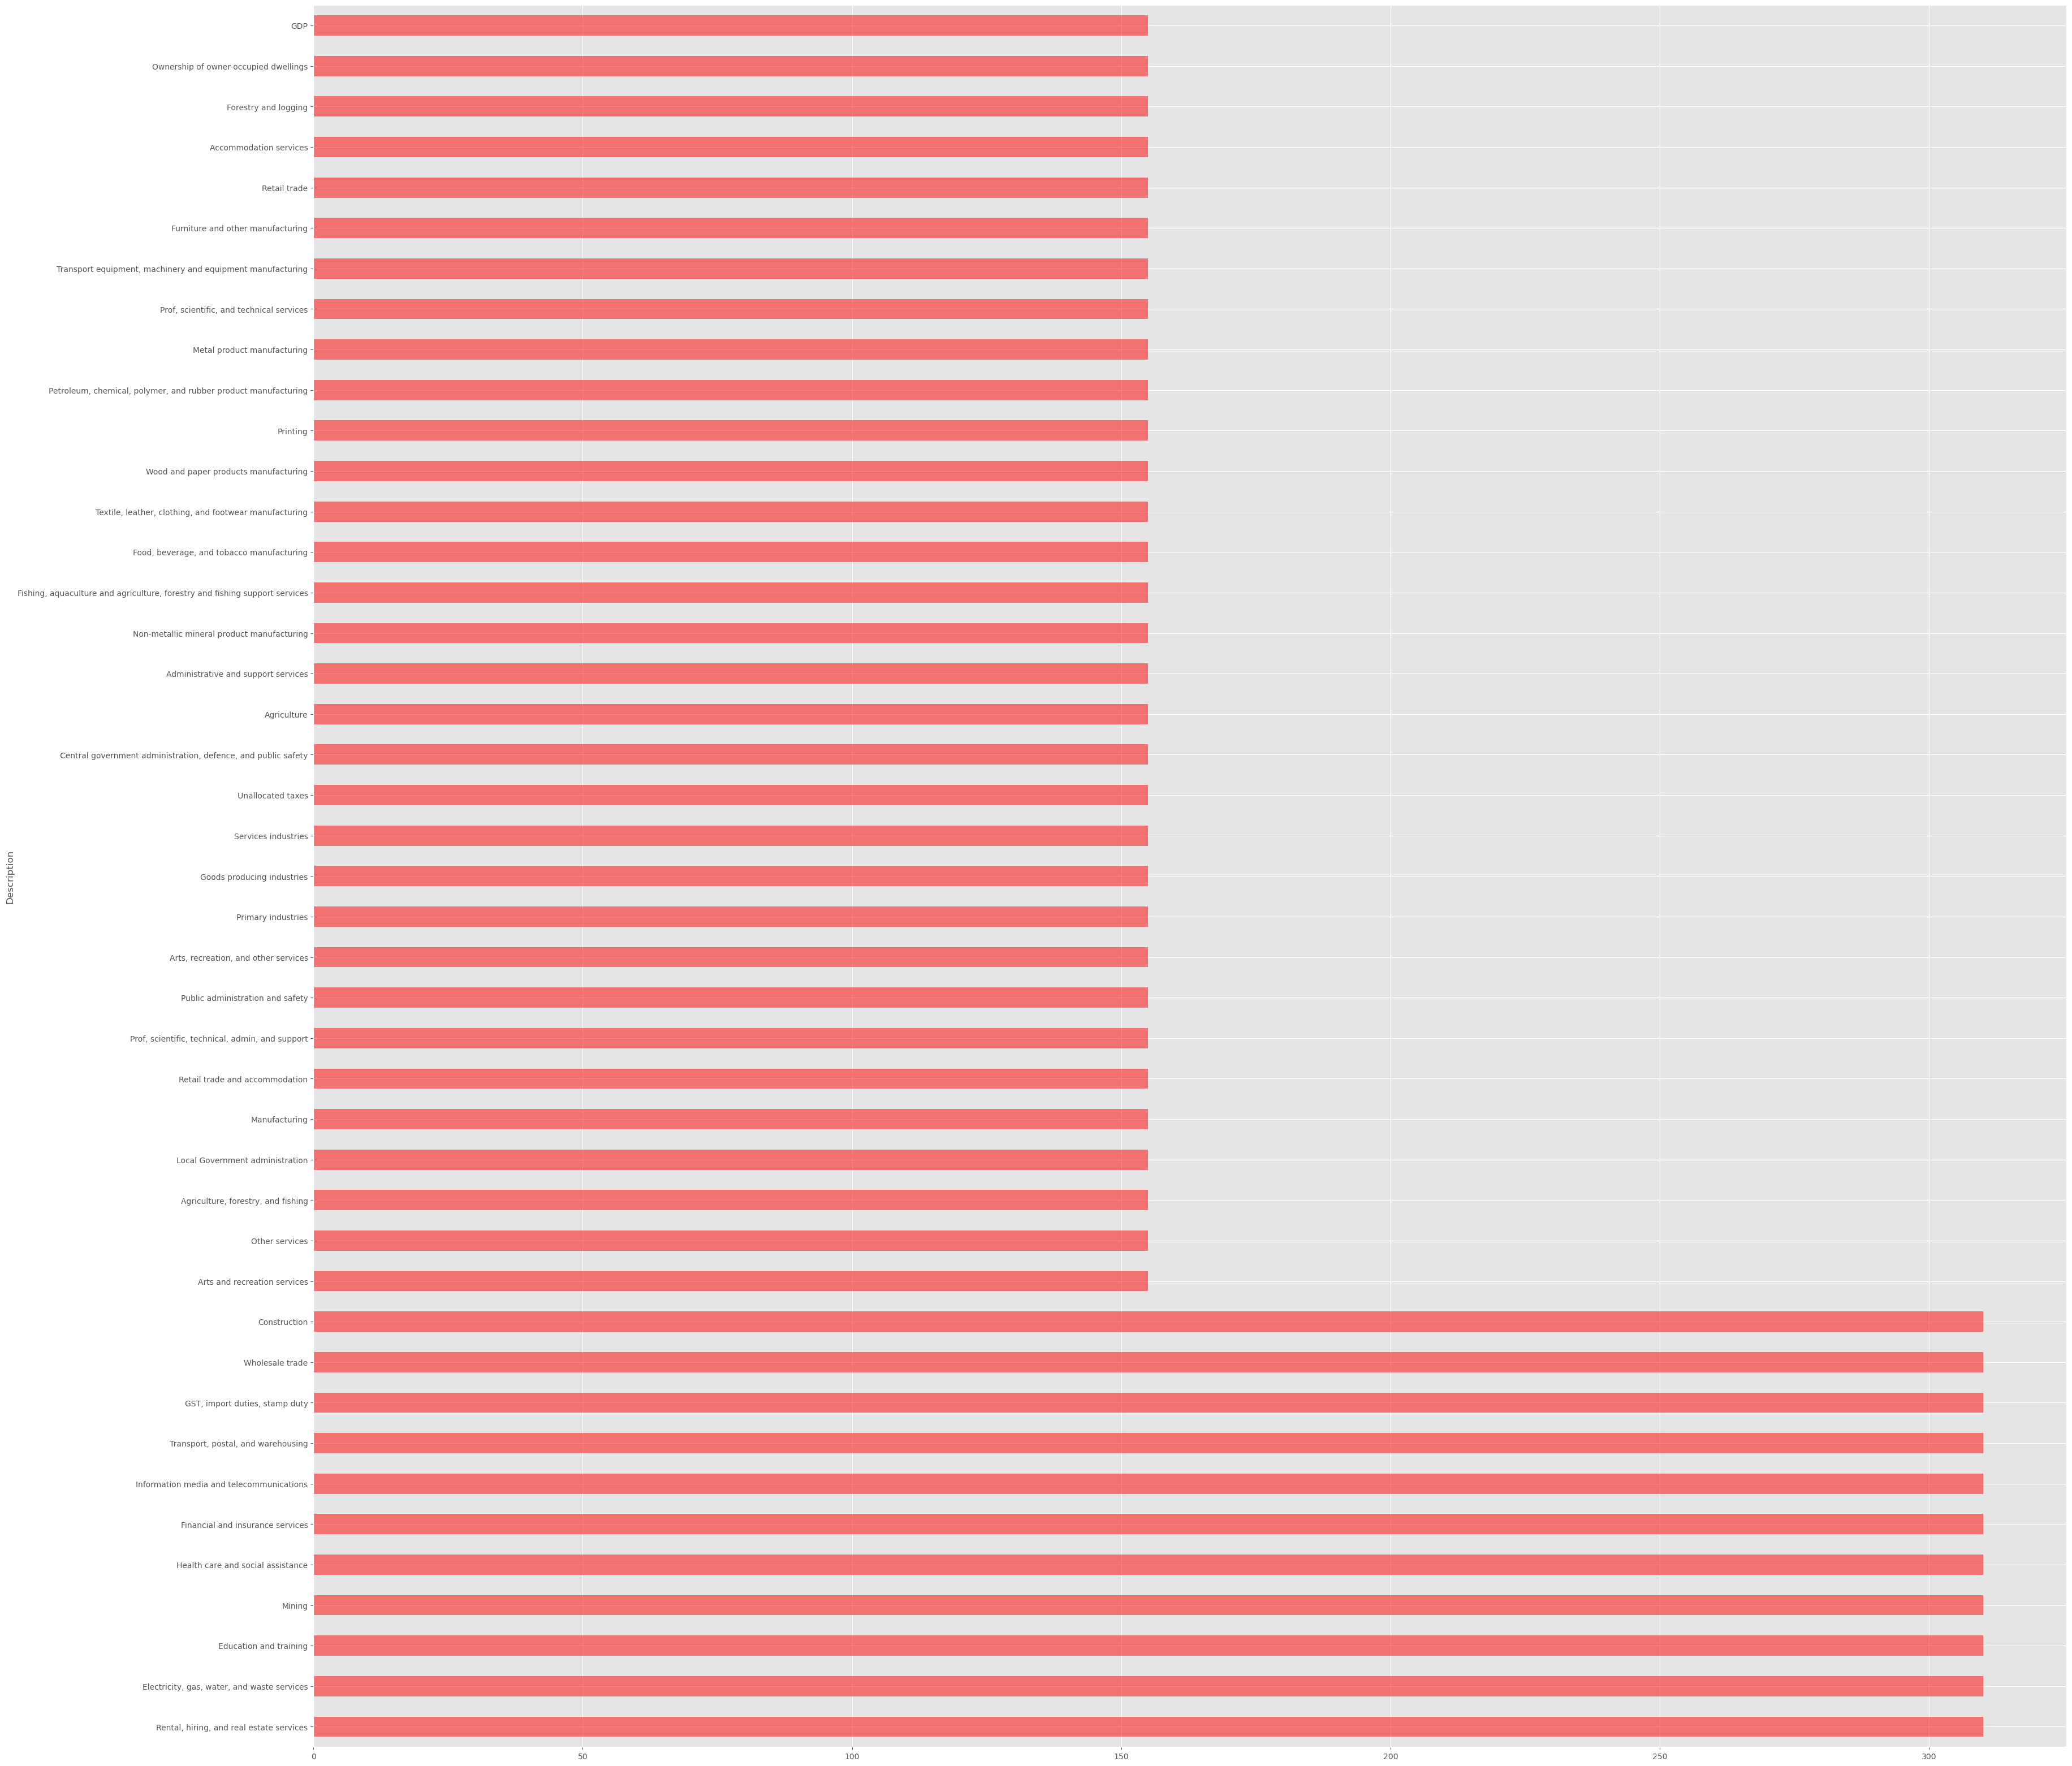

In [10]:
plt.style.use("ggplot")
plt.figure(figsize=(40,40))
df['Description'].value_counts().plot.barh(stacked=True, color='r',alpha=0.5)
plt.show()

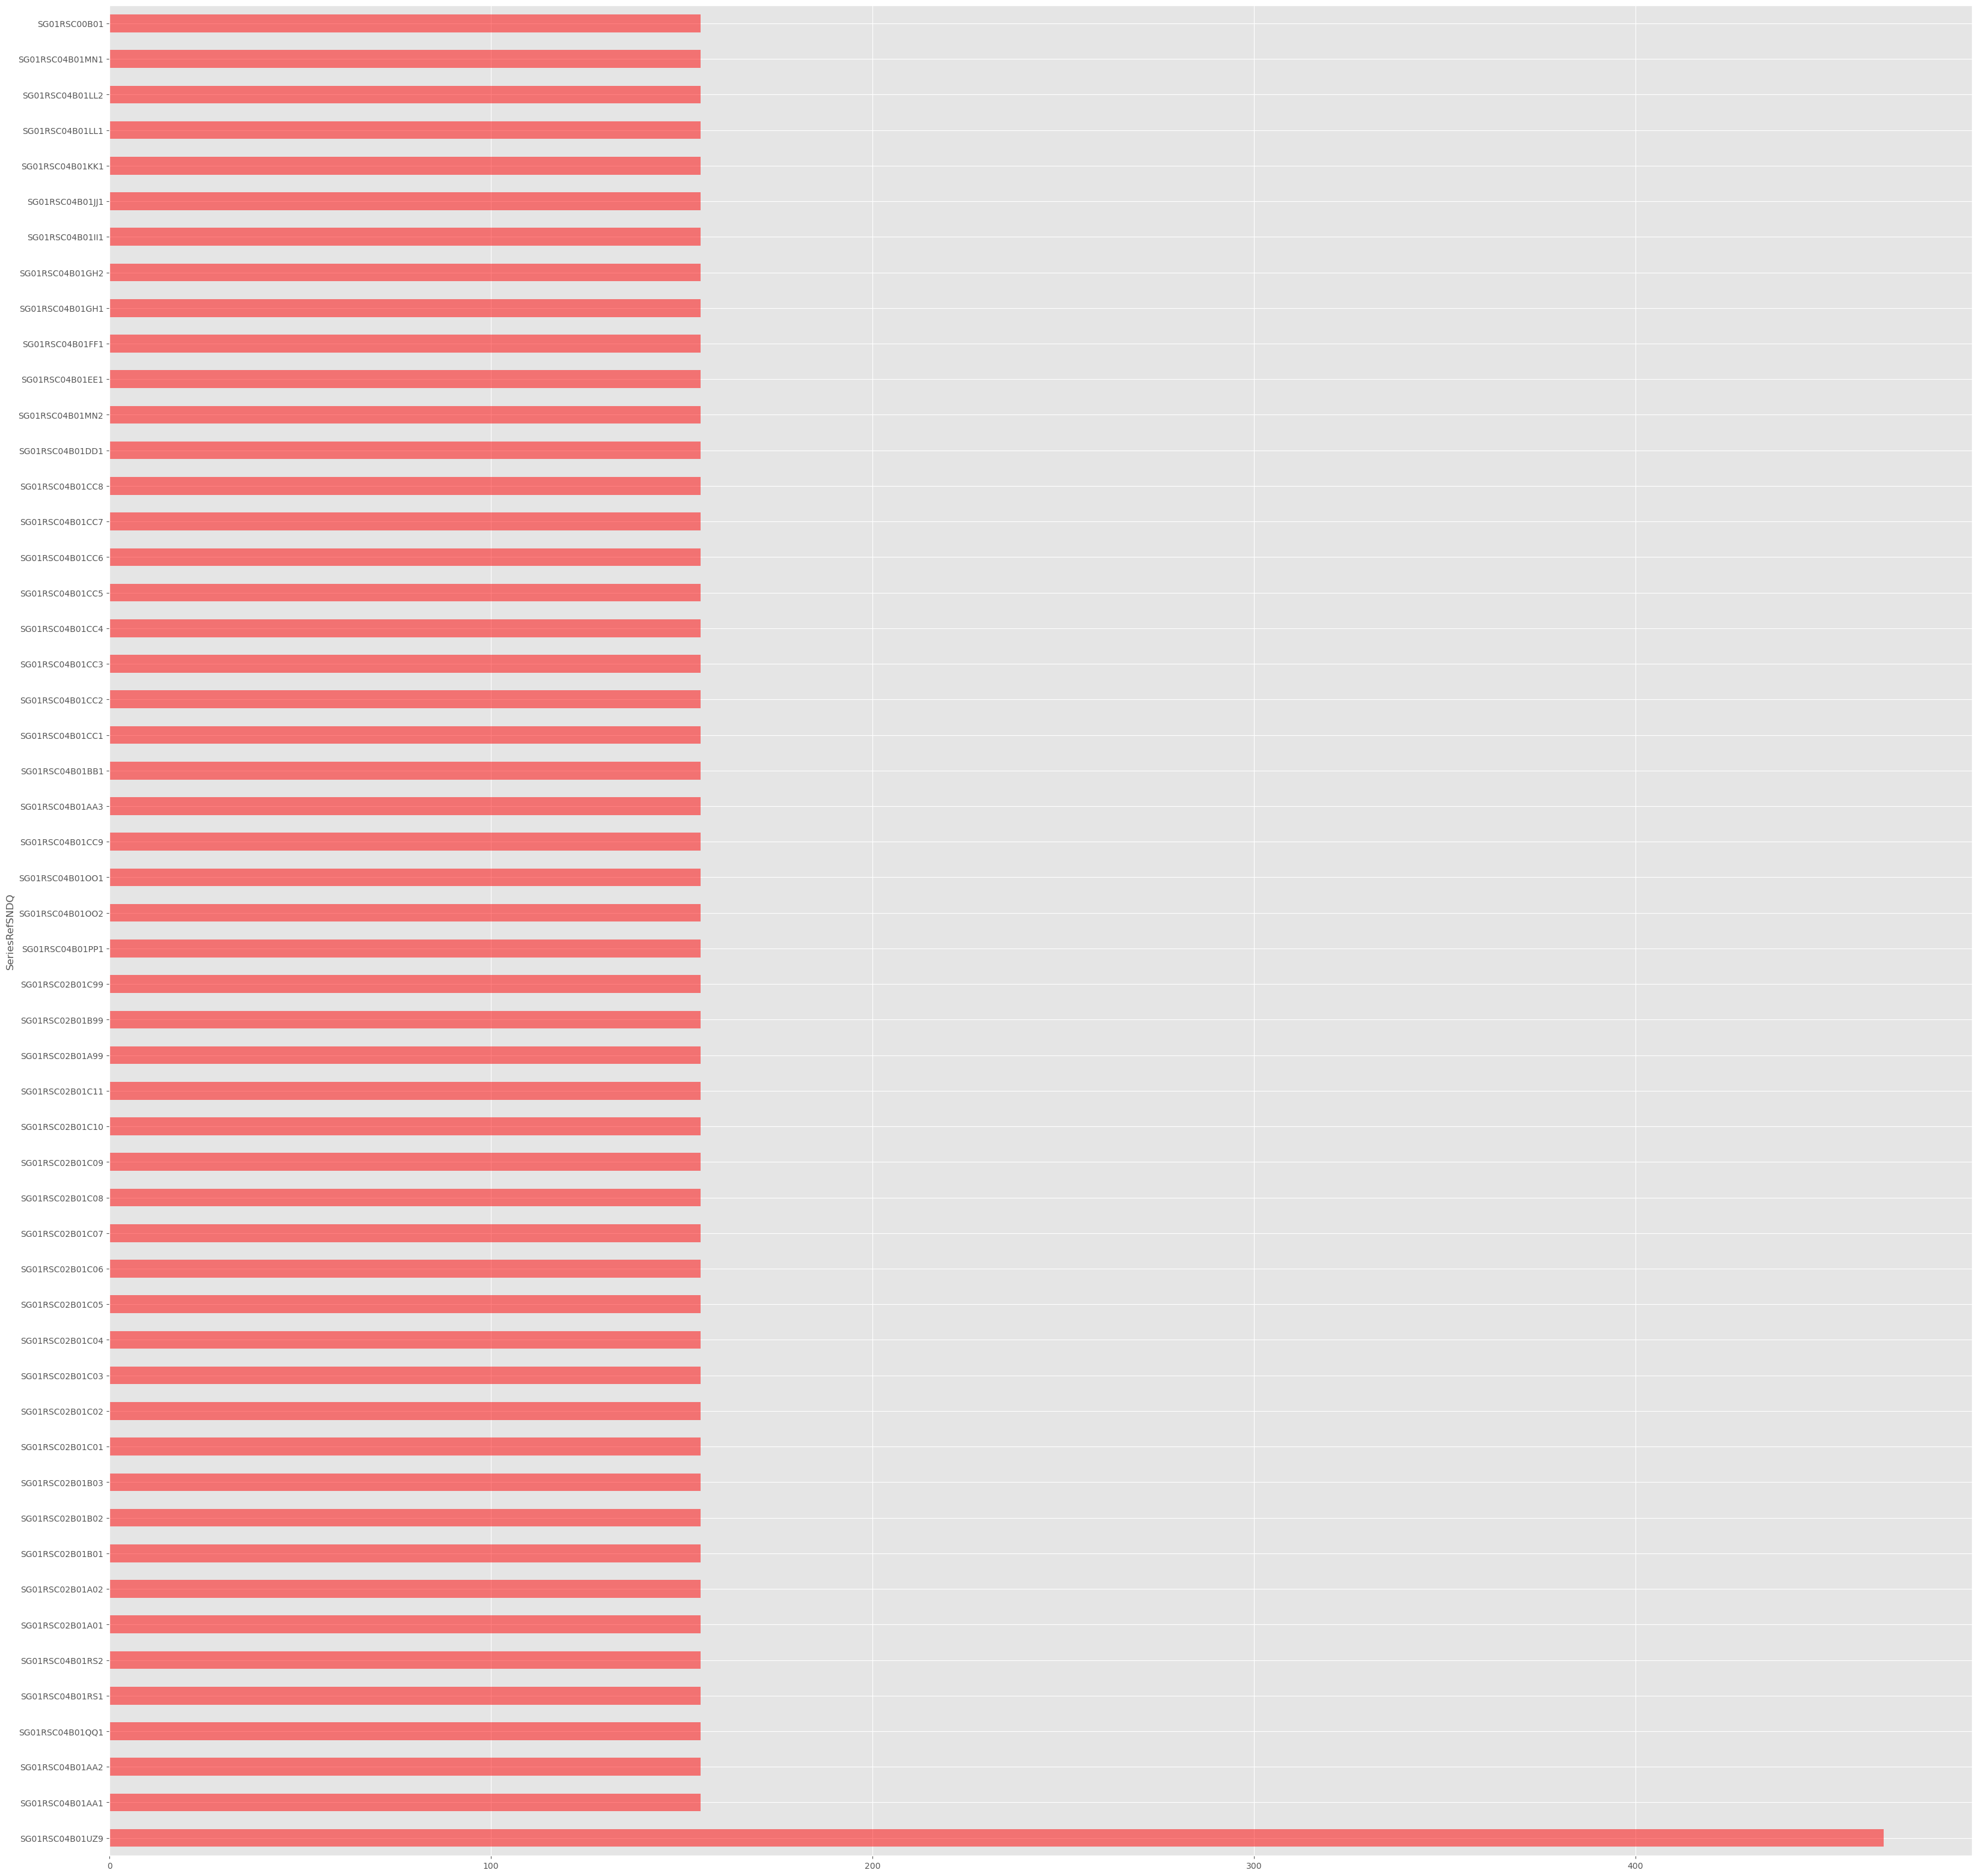

In [11]:
plt.style.use("ggplot")
plt.figure(figsize=(40,40))
df['SeriesRefSNDQ'].value_counts().plot.barh(stacked=True, color='r',alpha=0.5)
plt.show()

### Numerical Features

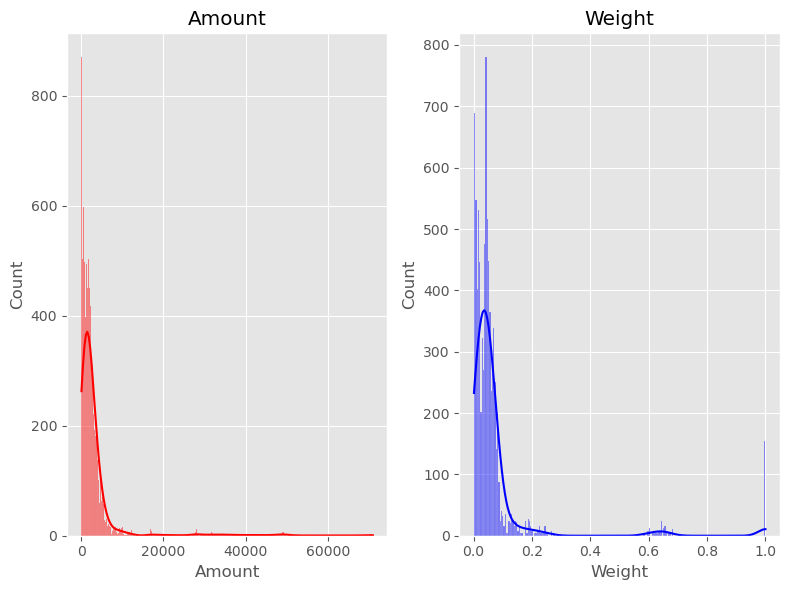

In [12]:
plt.figure(figsize=(8,6))
plt.subplot(121)
sns.histplot(x=df["Amount"], color="red", kde=True).set(title='Amount')
plt.title("Amount")
plt.autoscale()
plt.subplot(122)
sns.histplot(x=df["Weight"],color="blue", kde=True).set(title='Weight')
plt.title("Weight")
plt.tight_layout()
plt.show()

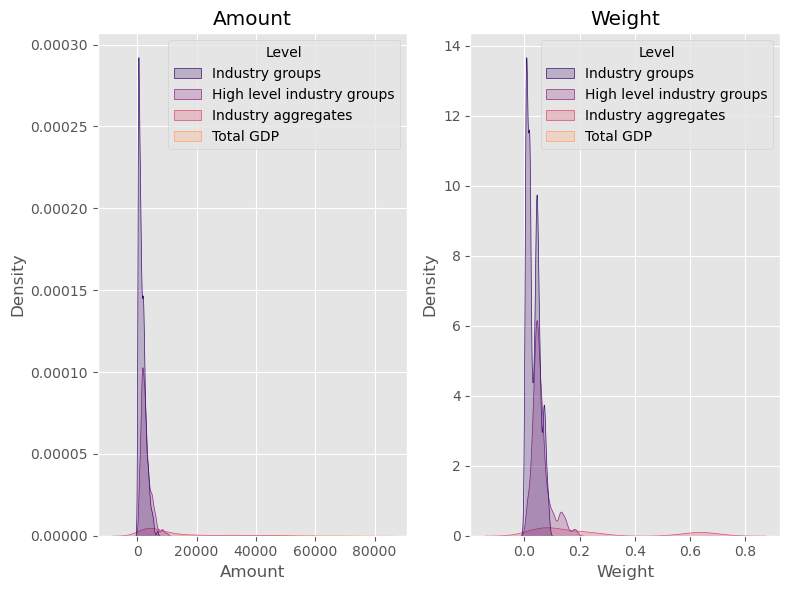

In [13]:
plt.figure(figsize=(8,6))
plt.subplot(121)
sns.kdeplot(x="Amount", data=df, hue="Level",fill="True", palette="magma").set(title="Amount")
plt.title("Amount")
plt.autoscale()
plt.subplot(122)
sns.kdeplot(x="Weight", data=df, hue="Level",fill="True", palette="magma",warn_singular=False).set(title="Weight")
plt.title("Weight")
plt.tight_layout()
plt.show()

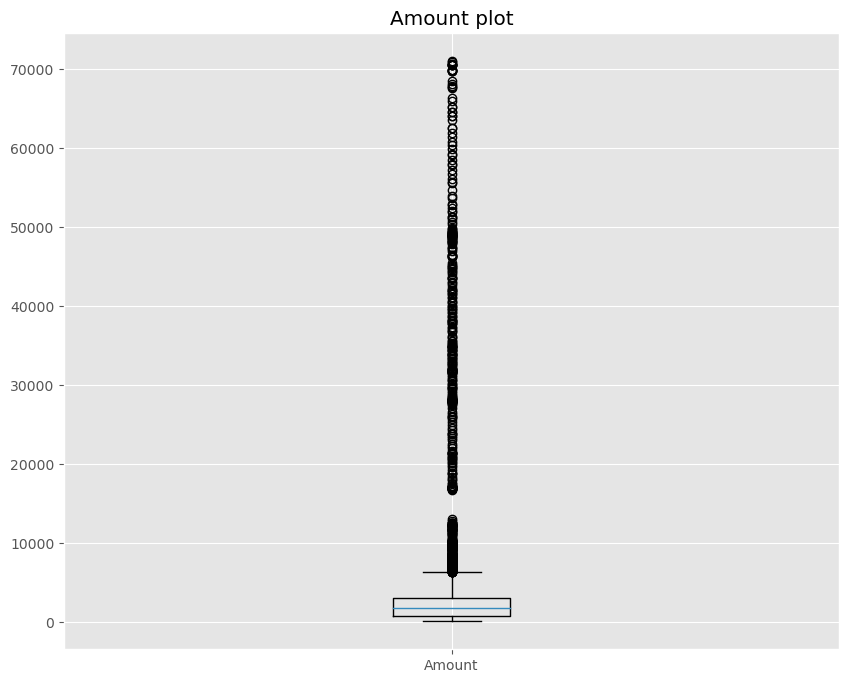

In [14]:
boxplot = plt.figure(figsize=(10,8))
plt.boxplot(df['Amount'],labels=['Amount'])
plt.title('Amount plot')
plt.show()

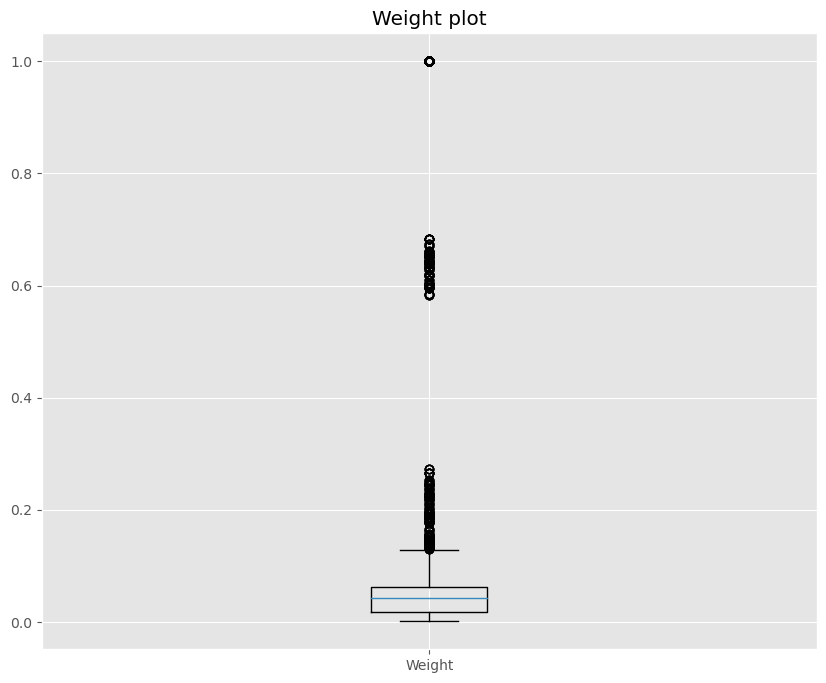

In [15]:
boxplot = plt.figure(figsize=(10,8))
plt.boxplot(df['Weight'],labels=['Weight'])
plt.title('Weight plot')
plt.show()

### Interpretations from the above boxplots.
* are lots of outliers in the numerical data above.*

In [16]:
X = df.drop(['Quarter','Amount','SeriesRefSNDQ'], axis=1)  # features
y = df['Amount']               # target = price

In [17]:
X

,Level,Description,Weight
0,Industry groups,Agriculture,0.049996
1,Industry groups,Forestry and logging,0.004201
2,Industry groups,"Fishing, aquaculture and agriculture, forestry...",0.006766
3,Industry groups,Mining,0.014021
4,Industry groups,"Food, beverage, and tobacco manufacturing",0.056429
...,...,...,...
8365,Total GDP,GDP,1.000000
8366,Total GDP,GDP,1.000000
8367,Total GDP,GDP,1.000000
8368,Total GDP,GDP,1.000000


In [18]:
y

0        1596.686
1         120.463
2         201.055
3         530.698
4        1145.595
          ...    
8365    69728.468
8366    70494.316
8367    69885.643
8368    70489.036
8369    70663.589
Name: Amount, Length: 8370, dtype: float64

### Split train/test

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# No stratify for regression - target is continuous

In [20]:
print("Shape of training set:", X_train.shape)
print("Shape of test set:", X_test.shape)

Shape of training set: (6696, 3)
Shape of test set: (1674, 3)


In [21]:
print(y_train.shape) 
print(y_test.shape) 

(6696,)
(1674,)


### Detect column types automatically

In [22]:
num_cols = X.select_dtypes(include=['float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

In [23]:
num_cols

Index(['Weight'], dtype='object')

In [24]:
cat_cols

Index(['Level', 'Description'], dtype='object')

### Preprocessing + Pipeline

In [25]:
# Regression also needs scaling, especially for LinearRegression, Ridge, SVR:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())  # use StandardScaler if no outliers
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
], remainder='drop')

### Pick regression model + full pipeline

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

pipe = Pipeline([
    ('prep', preprocessor),
    ('model', LinearRegression())  # baseline
    # Try RandomForestRegressor() for non-linear relationships
])

### Train

In [27]:
pipe.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  Index(['Weight'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Level', 'Description'], dtype='object'))])),
                ('model', LinearRegression())])

### Predict

In [28]:
y_pred = pipe.predict(X_test)

### Evaluate - use regression metrics

In [29]:
# Accuracy doesn’t exist for regression. Use these 3:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)  # in same units as target
mae = mean_absolute_error(y_test, y_pred)  # avg error in dollars
r2 = r2_score(y_test, y_pred)  # 1.0=perfect, 0=baseline

print(f"RMSE: {rmse:.3f}")  # typical error
print(f"MAE: {mae:.3f}")    # avg error  
print(f"R² Score: {r2:.3f}") # % variance explained
# R² = 0.8 means model explains 80% of price variation.

RMSE: 2507.008
MAE: 933.583
R² Score: 0.904


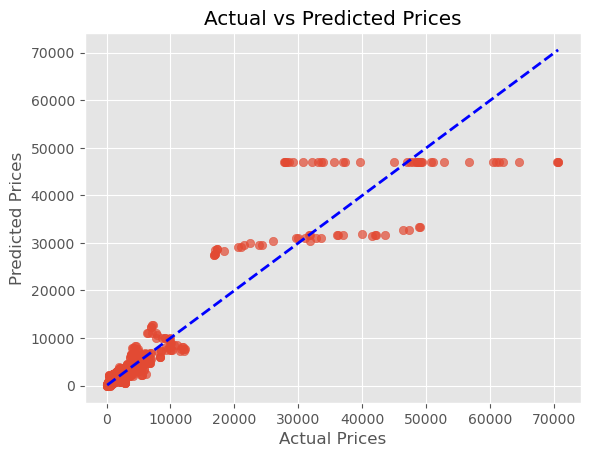

In [30]:
# Plot actual vs predicted prices
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)],linestyle='--', color='blue', linewidth=2)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices")
plt.show()

### Tune hyperparameters

* LinearRegression itself has no hyperparameter to tune. But except you can tune it by adding regularization or feature transform

* Define the Parameter Grid using double underscores '__' for pipeline tunning

# Other Method

In [31]:
numerical_cols = df[['Weight','Amount']]

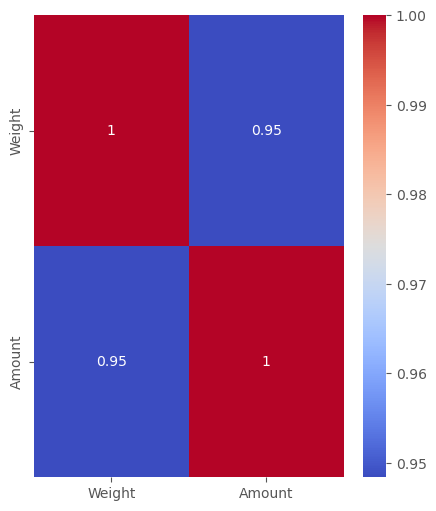

In [32]:
cor = numerical_cols.corr()
plt.figure(figsize=(5,6))
sns.heatmap(cor, cmap="coolwarm", annot=True)
plt.show()

In [33]:
df.columns

Index(['Level', 'Description', 'SeriesRefSNDQ', 'Quarter', 'Weight', 'Amount'], dtype='object')

In [34]:
X = df.drop(['Quarter','Amount','SeriesRefSNDQ'], axis=1)  # features
y = df['Amount']               # target = price

In [35]:
X

,Level,Description,Weight
0,Industry groups,Agriculture,0.049996
1,Industry groups,Forestry and logging,0.004201
2,Industry groups,"Fishing, aquaculture and agriculture, forestry...",0.006766
3,Industry groups,Mining,0.014021
4,Industry groups,"Food, beverage, and tobacco manufacturing",0.056429
...,...,...,...
8365,Total GDP,GDP,1.000000
8366,Total GDP,GDP,1.000000
8367,Total GDP,GDP,1.000000
8368,Total GDP,GDP,1.000000


In [36]:
y

0        1596.686
1         120.463
2         201.055
3         530.698
4        1145.595
          ...    
8365    69728.468
8366    70494.316
8367    69885.643
8368    70489.036
8369    70663.589
Name: Amount, Length: 8370, dtype: float64

### RandomForestRegressor

In [37]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, RobustScaler

In [38]:
# 2. Split data into train and test sets first to prevent leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [39]:
categorical_cols = ['Level','Description']
numeric_cols = ['Weight']

In [40]:
# 3. Scale numeric features
scaler = RobustScaler()
X_train_num_scaled = scaler.fit_transform(X_train[numeric_cols])
X_test_num_scaled = scaler.transform(X_test[numeric_cols])  # Note: Use transform, not fit_transform


In [41]:
# 4. Encode categorical features
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_train_cat_encoded = encoder.fit_transform(X_train[categorical_cols])
X_test_cat_encoded = encoder.transform(X_test[categorical_cols])  # Note: Use transform, not fit_transform


In [42]:
# 5. Combine numeric and categorical features back together
X_train_processed = np.hstack((X_train_num_scaled, X_train_cat_encoded))
X_test_processed = np.hstack((X_test_num_scaled, X_test_cat_encoded))

In [43]:
# 6. Train the Random Forest Regressor
regressor = RandomForestRegressor(n_estimators=100, random_state=42)
regressor.fit(X_train_processed, y_train)

RandomForestRegressor(random_state=42)

In [44]:
# 7. Make predictions
predictions = regressor.predict(X_test_processed)
print("Predictions:", predictions)

Predictions: [1820.90902075 3124.35367878  784.54856317 ... 1564.96327933 2537.64742454
 2212.6336176 ]


In [45]:
# Accuracy doesn’t exist for regression. Use these 3:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)  # in same units as target
mae = mean_absolute_error(y_test,predictions)  # avg error in dollars
r2 = r2_score(y_test, predictions)  # 1.0=perfect, 0=baseline

print(f"RMSE: {rmse:.3f}")  # typical error
print(f"MAE: {mae:.3f}")    # avg error  
print(f"R² Score: {r2:.3f}") # % variance explained
# R² = 0.8 means model explains 80% of price variation.

RMSE: 1975.587
MAE: 302.179
R² Score: 0.941


In [46]:
df= pd.DataFrame({'Actual':y_test,'Predictions':predictions})
df['Predictions']= round(df['Predictions'],2)
df.head()

,Actual,Predictions
5848,1892.427,1820.91
6839,3154.792,3124.35
5060,781.352,784.55
1345,207.806,204.34
6816,1621.812,1615.38


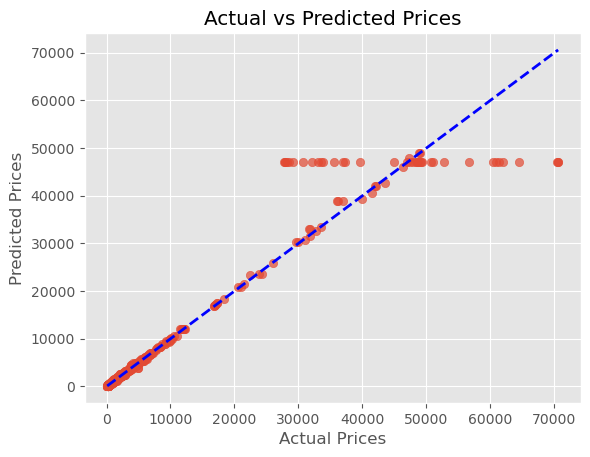

In [47]:
# Plot actual vs predicted prices
plt.scatter(y_test, predictions, alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)],linestyle='--', color='blue', linewidth=2)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices")
plt.show()

### Grid Search

In [ ]:
# 3. Parameter grid for tuning
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}
from sklearn.model_selection import GridSearchCV
# 4. GridSearchCV - use neg MSE since sklearn maximizes score
grid = GridSearchCV(
    estimator=regressor,
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    scoring='neg_mean_squared_error',
    verbose=1
)
grid.fit(X_train_processed, y_train)

# 5. Best params + CV score
print("Best params:", grid.best_params_)
print("Best CV RMSE:", np.sqrt(-grid.best_score_))


Fitting 5 folds for each of 216 candidates, totalling 1080 fits


In [ ]:
# 6. Test set performance
best_rf = grid.best_estimator_
y_pred = best_rf.predict(X_test_processed)
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("Test R2:", r2_score(y_test, predictions))

### RandomizedSearchCV

In [ ]:
# 3. Parameter distributions instead of fixed grid
from random import randint
param_dist = {
    'n_estimators': [100, 200, 300], # random 100-499
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', 0.5, 0.8]
}
from sklearn.model_selection import RandomizedSearchCV
from random import randint
# 4. RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=regressor,
    param_distributions=param_dist,
    n_iter=50, # only test 50 random combos
    cv=5,
    n_jobs=-1,
    scoring='neg_mean_squared_error',
    random_state=42,
    verbose=1
)
random_search.fit(X_train_processed, y_train)

# 5. Results
print("Best params:", random_search.best_params_)
print("Best CV RMSE:", np.sqrt(-random_search.best_score_))



In [ ]:
# 6. Test set performance
best_rf = random_search.best_estimator_
y_pred = best_rf.predict(X_test_processed)
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("Test R2:", r2_score(y_test, predictions))

## Lasso

In [ ]:
alpha = 1.0 # You can adjust the alpha parameter
lasso_model = Lasso(alpha=alpha)
lasso_model.fit(X_train_processed, y_train)

In [ ]:
# 7. Make predictions
predictionsL = lasso_model.predict(X_test_processed)
print("Predictions:", predictionsL)

In [ ]:
# Accuracy doesn’t exist for regression. Use these 3:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, predictionsL)
rmse = np.sqrt(mse)  # in same units as target
mae = mean_absolute_error(y_test,predictionsL)  # avg error in dollars
r2 = r2_score(y_test, predictionsL)  # 1.0=perfect, 0=baseline

print(f"RMSE: {rmse:.3f}")  # typical error
print(f"MAE: {mae:.3f}")    # avg error  
print(f"R² Score: {r2:.3f}") # % variance explained
# R² = 0.8 means model explains 80% of price variation.

In [ ]:
df= pd.DataFrame({'Actual':y_test,'Predictions':predictionsL})
df['Predictions']= round(df['Predictions'],2)
df.head()

In [ ]:
# Plot actual vs predicted prices
plt.scatter(y_test, predictionsL, alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)],linestyle='--', color='blue', linewidth=2)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices")
plt.show()

### Tune hyperparameters

In [ ]:
param_grid = {
    'random_state': [None, 10, 20, 30,40,50], # 1 = linear, 2 = add x^2, x1*x2 etc
    'alpha': np.logspace(-3, 3, 7) # 0.001 to 1000
}

# 4. GridSearchCV
grid = GridSearchCV(
    lasso_model,
    param_grid,
    cv=5,
    n_jobs=-1,
    scoring='neg_mean_squared_error'
)
grid.fit(X_train_processed, y_train)

# 5. Results
print("Best params:", grid.best_params_)
print("Best CV RMSE:", np.sqrt(-grid.best_score_))



In [ ]:
# 6. Test performance
y_pred = grid.predict(X_test_processed)
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, predictionsL)))
print("Test R2:", r2_score(y_test,predictionsL))

In [ ]:
Linear Regreesion
RMSE: 2507.008
MAE: 933.583
R² Score: 0.904

In [ ]:
Lasso
RMSE: 2515.175
MAE: 921.616
Test R2: 0.904

In [ ]:
Random Forest Regressor
Test RMSE: 1976.1797768126794
Test R2: 0.9406405592491079

From the above it shows that Random Forest Regressor gave us the best model for predicting the future sales. 